In [1]:
from pathlib import Path
import os
import sys
import json
import csv

ROOT = Path.cwd()
if not (ROOT / "data" / "manifests").exists():
    ROOT = Path(r"D:\\FILE AND TASK\\TA")
assert (ROOT / "data" / "manifests").exists(), ROOT
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["MPLBACKEND"] = "Agg"

try:
    from IPython.display import display, Image
except ImportError:
    def display(item): print(item)
    class Image:
        def __init__(self, filename): self.filename = filename

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Project:", ROOT)
print("Kernel:", sys.executable)


def show_json(path):
    print(path)
    print(json.dumps(json.loads(path.read_text(encoding="utf-8")), ensure_ascii=False, indent=2))


def show_csv(path, rows=30):
    frame = pd.read_csv(path, low_memory=False)
    print(path, "|", len(frame), "baris")
    display(frame if len(frame) <= rows else pd.concat([frame.head(rows // 2), frame.tail(rows // 2)]))
    if len(frame) > rows:
        print("Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.")
    return frame


Project: D:\FILE AND TASK\TA
Kernel: c:\Users\Fabio\AppData\Local\Programs\Python\Python314\python.exe


In [2]:
# Kode eksperimen berasal dari scripts/run_e4_five_locations_v10_stage7.py.draft dan ditempatkan langsung di notebook ini.
# Tidak ada pemanggilan subprocess atau eksekusi file runner eksternal.
# Entry point CLI sengaja tidak dipanggil otomatis agar artefak valid tidak tertimpa.
__file__ = str(ROOT / "scripts" / "run_e4_five_locations_v10_stage7.py.draft")

"""
Script: scripts/run_e4_domain_shift.py
Fungsi: Eksekusi Eksperimen E4 — Sensitivitas Profil Spektral Sumber Derau
        Lintas Habitat Lingkungan Nyata Kampus ITERA.
        Membandingkan ketahanan representasi (R0, R1, R2, R3) ketika kueri
        didegradasi oleh derau dari 3 profil akustik habitat berbeda di ITERA:
        1. Kebun Raya ITERA (Vegetasi Lebat Tropis / Dominasi Biophony Serangga)
        2. Embung F ITERA (Perairan Terbuka / Resonansi Air & Angin)
        3. Gedung F ITERA (Koridor Bangunan / Derau Struktural & Antropogenik)
"""

import os
import sys
import json
import hashlib
import argparse
import math
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(__file__).resolve().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocess import preprocess_audio, TARGET_SR
from src.embeddings import AudioRepresentationExtractor, R3_CONTROL_VERSION
from src.mix_noise import compute_signal_power, get_e3_reserved_noise_files
from src.retrieve import evaluate_retrieval_corpus
from scripts.e4_noise_identity_v1 import build_noise_identity
from scripts.e4_query_identity_v1 import build_query_audio_identity
from scripts.e4_run_identity_v2 import build_run_identity, fingerprint_json, sha256_file

SPLIT_PATH = PROJECT_ROOT / "data/manifests/dataset_split.csv"
NOISE_MANIFEST_PATH = PROJECT_ROOT / "data/manifests/itera_noise_manifest.csv"
NOISE_DIR = PROJECT_ROOT / "data/itera_noise"
FEATURES_DIR = PROJECT_ROOT / "results/features"
# Seluruh output E4 lima lokasi disimpan terpisah dari hasil historis.
RUN_TIMESTAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
E4_RUN_DIR = PROJECT_ROOT / "results/reproductions" / f"E4_5sites_{RUN_TIMESTAMP}"

PROCESSED_DIR = E4_RUN_DIR / "processed"
RAW_DIR = E4_RUN_DIR / "raw"
TABLES_DIR = E4_RUN_DIR / "tables"
FIG_DIR = E4_RUN_DIR / "figures"
PAPER_FIG_DIR = E4_RUN_DIR / "paper_figures"

def prepare_new_run_directories():
    if E4_RUN_DIR.exists():
        raise FileExistsError(f"Folder hasil sudah ada: {E4_RUN_DIR}")

    for d in [PROCESSED_DIR, RAW_DIR, TABLES_DIR, FIG_DIR, PAPER_FIG_DIR]:
        d.mkdir(parents=True, exist_ok=False)


def load_habitat_noise_files():
    """Mengelompokkan berkas derau ITERA berdasarkan 3 profil habitat utama (eksklusif dari unknown E3)."""
    df_noise = pd.read_csv(NOISE_MANIFEST_PATH)
    e3_reserved = get_e3_reserved_noise_files()
    habitats = {
        "Kebun_Raya": [],
        "Embung_F": [],
        "Gedung_F": [],
        "Masjid_At_Tanwir": [],
        "Sekitar_GKU_1": []
    }
    for _, r in df_noise.iterrows():
        fn = r["filename"]
        p = NOISE_DIR / fn
        if not p.exists() or p.name.lower() in e3_reserved:
            continue
        if "Kebun Raya" in fn:
            habitats["Kebun_Raya"].append(p)
        elif "Embung F" in fn:
            habitats["Embung_F"].append(p)
        elif "Gedung F" in fn:
            habitats["Gedung_F"].append(p)
        elif "Masjid At-tanwir" in fn:
            habitats["Masjid_At_Tanwir"].append(p)
        elif "Sekitar GKU 1" in fn:
            habitats["Sekitar_GKU_1"].append(p)

    for hab, files in habitats.items():
        print(f"[*] Habitat [{hab}]: {len(files)} berkas audio derau valid (disjoint dari E3).")
        if len(files) == 0:
            raise FileNotFoundError(f"Tidak ada berkas derau untuk habitat {hab}!")
    return habitats


def get_habitat_noise_segment(files: list, samples: int, seed: int = 42, return_path: bool = False,
                              return_audit_info: bool = False):
    """Mengambil segmen acak dari daftar berkas derau habitat tertentu dengan penolakan derau senyap."""
    rng = np.random.default_rng(seed)
    max_attempts = 10
    for attempt in range(max_attempts):
        selected = files[rng.integers(0, len(files))]
        try:
            y, _ = librosa.load(str(selected), sr=TARGET_SR, mono=True)
            if len(y) >= samples:
                start = int(rng.integers(0, len(y) - samples + 1))
                seg = y[start:start + samples].astype(np.float32)
            else:
                repeats = int(np.ceil(samples / len(y)))
                y = np.tile(y, repeats)
                seg = y[:samples].astype(np.float32)
                start = 0

            raw_rms = np.sqrt(np.mean(seg ** 2))
            if raw_rms < 1e-4:
                continue

            try:
                rel_path = str(Path(selected).relative_to(NOISE_DIR)).replace("\\", "/")
            except ValueError:
                rel_path = Path(selected).name

            audit_info = {
                "noise_file": rel_path,
                "noise_start_sample": start,
                "noise_segment_samples": int(samples),
                "noise_seed": int(seed),
                "noise_attempt": attempt + 1,
                "noise_raw_rms": float(raw_rms),
            }
            if return_audit_info:
                return seg, audit_info
            if return_path:
                return seg, rel_path
            return seg
        except Exception as e:
            if attempt == max_attempts - 1:
                raise RuntimeError(f"Gagal memuat derau habitat {selected}: {e}")

    raise ValueError(f"[FATAL] Terdeteksi segmen derau senyap pada habitat setelah {max_attempts} percobaan pengambilan!")


def mix_with_habitat_noise(clean: np.ndarray, noise_files: list, snr_db: float, seed: int = 42,
                           return_noise_path: bool = False, return_audit_info: bool = False):
    """Mencampur sinyal bersih dengan derau habitat tertentu pada SNR eksak."""
    noise, audit_info = get_habitat_noise_segment(noise_files, samples=len(clean), seed=seed, return_audit_info=True)
    rel_path = audit_info["noise_file"]
    p_signal = compute_signal_power(clean)
    p_noise = compute_signal_power(noise)

    if p_signal <= 1e-12:
        audit_info.update({
            "snr_db_target": float(snr_db), "snr_db_achieved": None,
            "signal_power": p_signal, "noise_power_before_scaling": p_noise,
            "noise_gain": None, "post_mix_gain": 1.0, "mix_skipped_silent_signal": True,
        })
        if return_audit_info:
            return clean.copy(), audit_info
        if return_noise_path:
            return clean.copy(), rel_path
        return clean.copy()

    if p_noise <= 1e-10:
        raise ValueError(f"[FATAL] Derau fisik habitat terdeteksi senyap ({rel_path})!")

    target_p_noise = p_signal / (10.0 ** (snr_db / 10.0))
    alpha = np.sqrt(target_p_noise / p_noise)
    scaled_noise = alpha * noise
    noisy = clean + scaled_noise

    max_amp = np.max(np.abs(noisy))
    post_mix_gain = 1.0 / max_amp if max_amp > 1.0 else 1.0
    noisy = noisy * post_mix_gain
    signal_after_gain = clean * post_mix_gain
    noise_after_gain = scaled_noise * post_mix_gain
    achieved_snr = 10.0 * np.log10(compute_signal_power(signal_after_gain) / compute_signal_power(noise_after_gain))
    audit_info.update({
        "snr_db_target": float(snr_db), "snr_db_achieved": float(achieved_snr),
        "signal_power": p_signal, "noise_power_before_scaling": p_noise,
        "noise_gain": float(alpha), "post_mix_gain": float(post_mix_gain), "mix_skipped_silent_signal": False,
    })

    res = noisy.astype(np.float32)
    if return_audit_info:
        return res, audit_info
    if return_noise_path:
        return res, rel_path
    return res


# Snapshot protocol: CSV finalized first, sidecar JSON published last.
# Interrupted writes are rejected (never implicitly overwritten).
SNAPSHOT_SCHEMA = "E4_condition_snapshot_v1"
SUMMARY_KEYS = {
    "representation", "repeat_id", "habitat", "condition", "snr_db",
    "mAP@10", "Top1_Accuracy", "Precision@10", "Recall@10", "relative_retention",
}


def write_json_new(path, data):
    """Create an immutable identity file without overwriting prior runs."""
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    if path.exists() or temporary.exists():
        raise FileExistsError(f"Sudah ada identitas atau file parsial: {path}")
    encoded = (json.dumps(data, ensure_ascii=False, indent=2, sort_keys=True, allow_nan=False) + "\n").encode("utf-8")
    with temporary.open("xb") as stream:
        stream.write(encoded)
        stream.flush()
        os.fsync(stream.fileno())
    temporary.replace(path)


def write_df_replace(df, path):
    """Atomically regenerate derived aggregate outputs only."""
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    if temp.exists():
        raise FileExistsError(f"File keluaran sementara perlu diperiksa: {temp}")
    with temp.open("x", newline="", encoding="utf-8") as stream:
        df.to_csv(stream, index=False)
        stream.flush()
        os.fsync(stream.fileno())
    temp.replace(path)


def validate_run_identity(identity_path, expected_identity, expected_hash):
    if not identity_path.is_file():
        raise FileNotFoundError(f"Resume ditolak; identitas tidak ada: {identity_path}")
    data = json.loads(identity_path.read_text(encoding="utf-8"))
    if set(data) != {"identity", "sha256"}:
        raise ValueError("Format run_identity.json tidak sah.")
    if fingerprint_json(data["identity"]) != data["sha256"]:
        raise ValueError("Checksum run_identity.json tidak valid.")
    if data["sha256"] != expected_hash or data["identity"] != expected_identity:
        raise ValueError("Resume ditolak: run identity berbeda dari aset/desain/kode aktif.")


def _expected_pool_names(pool, noise_dir):
    return {Path(p).relative_to(noise_dir).as_posix() for p in pool}


def validate_condition_rows(frame, summary, query_df, config_per_query,
                            habitat_pools, noise_dir, rep, repeat_id, habitat, snr):
    """Fail-closed semantic validation of 311 ordered query records + summary."""
    required = {
        "query_id", "species_key", "representation", "repeat_id", "habitat",
        "condition", "snr_db", "noise_file", "noise_config", "noise_seed",
        "noise_start_sample", "noise_segment_samples", "noise_raw_rms",
        "snr_db_target", "snr_db_achieved", "mix_skipped_silent_signal",
    }
    if not required.issubset(frame.columns):
        raise ValueError(f"Kolom snapshot kurang: {sorted(required - set(frame.columns))}")
    if len(frame) != len(query_df) or len(frame) != 311:
        raise ValueError("Snapshot tidak berisi 311 Query.")
    if frame["query_id"].astype(str).tolist() != query_df["recording_id"].astype(str).tolist():
        raise ValueError("Urutan ID Query snapshot salah.")
    if frame["species_key"].astype(str).tolist() != query_df["species_key"].astype(str).tolist():
        raise ValueError("Urutan label Query snapshot salah.")
    if frame["noise_config"].astype(str).tolist() != config_per_query:
        raise ValueError("Kategori noise per Query berubah.")
    scalar_columns = {
        "representation": rep, "repeat_id": repeat_id, "habitat": habitat,
        "condition": f"SNR_{snr}dB", "snr_db": snr,
    }
    for key, value in scalar_columns.items():
        values = frame[key].tolist()
        if any(str(x) != str(value) for x in values):
            raise ValueError(f"Kolom kondisi snapshot tidak cocok: {key}")
    seeds = pd.to_numeric(frame["noise_seed"], errors="raise").to_numpy()
    expected_seeds = np.array([5000 + 100000 * repeat_id + i for i in range(len(frame))])
    if not np.array_equal(seeds, expected_seeds):
        raise ValueError("Seed snapshot tidak cocok.")
    allowed = {name: _expected_pool_names(paths, noise_dir) for name, paths in habitat_pools.items()}
    for config, noise_file in zip(config_per_query, frame["noise_file"].astype(str)):
        if noise_file not in allowed[config]:
            raise ValueError(f"Berkas noise bukan kandidat kategori aktif: {noise_file}")
    starts = pd.to_numeric(frame["noise_start_sample"], errors="raise").to_numpy()
    lengths = pd.to_numeric(frame["noise_segment_samples"], errors="raise").to_numpy()
    rms = pd.to_numeric(frame["noise_raw_rms"], errors="raise").to_numpy()
    targets = pd.to_numeric(frame["snr_db_target"], errors="raise").to_numpy()
    if not (np.isfinite(starts).all() and (starts >= 0).all()
            and np.isfinite(lengths).all() and (lengths > 0).all()
            and np.isfinite(rms).all() and (rms >= 1e-4).all()
            and np.isfinite(targets).all()
            and np.allclose(targets, snr, rtol=0, atol=1e-8)):
        raise ValueError("Audit noise snapshot tidak valid.")
    skipped = frame["mix_skipped_silent_signal"].astype(str).str.lower()
    if not skipped.isin(["true", "false"]).all():
        raise ValueError("Flag sinyal senyap tidak valid.")
    actual_snr = pd.to_numeric(frame["snr_db_achieved"], errors="coerce").to_numpy()
    not_skipped = (skipped == "false").to_numpy()
    if not (np.isfinite(actual_snr[not_skipped]).all()
            and np.allclose(actual_snr[not_skipped], snr, atol=0.1, rtol=0)):
        raise ValueError("SNR hasil mixing snapshot salah.")
    if set(summary) != SUMMARY_KEYS:
        raise ValueError("Struktur ringkasan snapshot salah.")
    for key, value in scalar_columns.items():
        if summary[key] != value:
            raise ValueError(f"Ringkasan snapshot salah: {key}")
    for key in ("mAP@10", "Top1_Accuracy", "Precision@10", "Recall@10"):
        number = float(summary[key])
        if not math.isfinite(number) or not 0 <= number <= 1:
            raise ValueError(f"Ringkasan numerik invalid: {key}")
    retention = float(summary["relative_retention"])
    if not math.isfinite(retention) or retention < 0:
        raise ValueError("Retensi tidak valid.")
    # Where raw metrics are available in compatible naming, additionally check means.
    for summary_key, aliases in (
        ("mAP@10", ("AP@10", "ap_at_10", "average_precision_at_10")),
        ("Top1_Accuracy", ("top1_correct", "top1_accuracy")),
        ("Precision@10", ("Precision@10", "precision_at_10")),
        ("Recall@10", ("Recall@10", "recall_at_10")),
    ):
        for alias in aliases:
            if alias in frame.columns:
                observed = pd.to_numeric(frame[alias], errors="raise").to_numpy()
                if not np.isfinite(observed).all() or not np.isclose(
                    observed.mean(), float(summary[summary_key]), atol=1e-8, rtol=0
                ):
                    raise ValueError(f"Metrik summary tidak sesuai kolom {alias}.")
                break


def load_condition_snapshot(csv_path, run_sha, query_df, config_per_query,
                            habitat_pools, noise_dir, rep, repeat_id, habitat, snr):
    csv_path = Path(csv_path)
    sidecar_path = csv_path.with_suffix(".json")
    if not csv_path.is_file() or not sidecar_path.is_file():
        raise FileNotFoundError(f"Pasangan snapshot CSV/JSON tidak lengkap: {csv_path}")
    meta = json.loads(sidecar_path.read_text(encoding="utf-8"))
    if set(meta) != {"schema", "run_sha256", "csv_sha256", "query_count", "summary"}:
        raise ValueError(f"Metadata snapshot tidak lengkap: {sidecar_path}")
    if meta["schema"] != SNAPSHOT_SCHEMA or meta["run_sha256"] != run_sha:
        raise ValueError(f"Snapshot beda run atau schema: {csv_path}")
    if meta["csv_sha256"] != sha256_file(csv_path):
        raise ValueError(f"Checksum snapshot CSV berubah: {csv_path}")
    if meta["query_count"] != len(query_df):
        raise ValueError("Jumlah Query metadata snapshot salah.")
    frame = pd.read_csv(csv_path, dtype={"query_id": str, "species_key": str, "noise_file": str})
    validate_condition_rows(frame, meta["summary"], query_df, config_per_query,
                            habitat_pools, noise_dir, rep, repeat_id, habitat, snr)
    return meta["summary"], frame.to_dict(orient="records")


def save_condition_snapshot(csv_path, rows, summary, run_sha, query_df,
                            config_per_query, habitat_pools, noise_dir):
    csv_path = Path(csv_path)
    json_path = csv_path.with_suffix(".json")
    temp = csv_path.with_name(csv_path.name + ".tmp")
    if any(p.exists() for p in (csv_path, json_path, temp, json_path.with_name(json_path.name + ".tmp"))):
        raise FileExistsError(f"Snapshot sudah ada atau parsial: {csv_path}")
    validate_condition_rows(pd.DataFrame(rows), summary, query_df, config_per_query,
                            habitat_pools, noise_dir, summary["representation"],
                            summary["repeat_id"], summary["habitat"], summary["snr_db"])
    with temp.open("x", newline="", encoding="utf-8") as stream:
        pd.DataFrame(rows).to_csv(stream, index=False)
        stream.flush()
        os.fsync(stream.fileno())
    temp.replace(csv_path)
    # Cross-check round-trip BEFORE publishing the completion marker.
    meta = {
        "schema": SNAPSHOT_SCHEMA,
        "run_sha256": run_sha,
        "csv_sha256": sha256_file(csv_path),
        "query_count": len(query_df),
        "summary": summary,
    }
    frame = pd.read_csv(csv_path, dtype={"query_id": str, "species_key": str, "noise_file": str})
    validate_condition_rows(frame, summary, query_df, config_per_query,
                            habitat_pools, noise_dir, summary["representation"],
                            summary["repeat_id"], summary["habitat"], summary["snr_db"])
    write_json_new(json_path, meta)


def precheck_snapshots(raw_dir, representations, habitats, snrs, query_df,
                       config_per_query, habitat_pools, run_sha):
    """Validate all existing conditions before any inference or output modifications."""
    found = {}
    for rep in representations:
        base = raw_dir / f"E4_{rep}_conditions"
        if not base.is_dir():
            # Run mungkin terhenti sebelum representasi berikutnya dimulai.
            continue
        for repeat_id in range(4):
            repeat_dir = base / f"repeat_{repeat_id}"
            if not repeat_dir.is_dir():
                continue  # crash before first condition of a repeat
            expected = {f"{hab}_SNR_{snr}dB" for hab in habitats for snr in snrs}
            for filename in repeat_dir.iterdir():
                if filename.is_symlink():
                    raise ValueError(f"Symlink dalam checkpoint tidak diizinkan: {filename}")
                if not filename.is_file() or filename.suffix not in (".csv", ".json") or filename.stem not in expected:
                    raise ValueError(f"File snapshot tidak dikenal/parsial: {filename}")
            for hab in habitats:
                for snr in snrs:
                    csv = repeat_dir / f"{hab}_SNR_{snr}dB.csv"
                    sidecar = csv.with_suffix(".json")
                    if not csv.exists() and not sidecar.exists():
                        continue
                    result = load_condition_snapshot(
                        csv, run_sha, query_df, config_per_query,
                        habitat_pools[hab], NOISE_DIR, rep, repeat_id, hab, snr,
                    )
                    found[(rep, repeat_id, hab, snr)] = result
    return found


def main():
    global E4_RUN_DIR, PROCESSED_DIR, RAW_DIR, TABLES_DIR, FIG_DIR, PAPER_FIG_DIR
    parser = argparse.ArgumentParser(description="E4 lima lokasi dengan resume beridentitas")
    parser.add_argument("--resume-dir", type=Path, help="Folder E4_5sites_* yang sudah memiliki run_identity.json")
    parser.add_argument("--preflight-only", action="store_true", help="Validasi aset dan identitas tanpa output/inferensi")
    args = parser.parse_args()
    if args.resume_dir is not None:
        allowed_parent = (PROJECT_ROOT / "results/reproductions").resolve()
        requested = args.resume_dir.resolve()
        if requested.parent != allowed_parent or not requested.name.startswith("E4_5sites_"):
            raise ValueError("--resume-dir harus menunjuk langsung ke folder E4_5sites_* dalam proyek")
        if not requested.is_dir():
            raise FileNotFoundError(requested)
        E4_RUN_DIR = requested
    PROCESSED_DIR = E4_RUN_DIR / "processed"
    RAW_DIR = E4_RUN_DIR / "raw"
    TABLES_DIR = E4_RUN_DIR / "tables"
    FIG_DIR = E4_RUN_DIR / "figures"
    PAPER_FIG_DIR = E4_RUN_DIR / "paper_figures"
    print("=" * 80)
    print("[*] MEMULAI E4: SENSITIVITAS PROFIL SPEKTRAL DERAU LINTAS HABITAT KAMPUS ITERA")
    print("=" * 80)

    habitats = load_habitat_noise_files()

    noise_identity, noise_fingerprint = build_noise_identity(
        habitats,
        NOISE_MANIFEST_PATH,
        NOISE_DIR,
        get_e3_reserved_noise_files(),
    )
    print(
        "[E4] Fingerprint kandidat noise terurut:",
        noise_fingerprint,
        flush=True,
    )

    df_split = pd.read_csv(SPLIT_PATH)
    gallery_df = df_split[df_split["split_role"] == "gallery"].reset_index(drop=True)
    query_df = df_split[df_split["split_role"] == "query_clean"].reset_index(drop=True)

    query_audio_identity, query_audio_fingerprint = (
        build_query_audio_identity(query_df, PROJECT_ROOT)
    )
    print(
        "[E4] Fingerprint audio Query terurut:",
        query_audio_fingerprint,
        flush=True,
    )

    print(f"[*] Total Galeri: {len(gallery_df)}, Total Kueri: {len(query_df)}")

    # PREFLIGHT: validasi semua cache Clean R1/R2/R3
    # sebelum komputasi noisy R0 dimulai.
    cache_folders = {
        "R1": PROJECT_ROOT / (
            "results/reproductions/"
            "E4_clean_cache_R1_20261011T204428_478762Z"
        ),
        "R2": PROJECT_ROOT / (
            "results/reproductions/"
            "E4_clean_cache_R2_20261011T204031_982072Z"
        ),
        "R3": PROJECT_ROOT / (
            "results/reproductions/"
            "E4_clean_cache_R3_20261011T203439_269234Z"
        ),
    }

    expected_dims = {"R1": 2048, "R2": 1024, "R3": 40}
    manifest_hash = hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest()

    expected_gal_ids = gallery_df["recording_id"].astype(str).tolist()
    expected_qry_ids = query_df["recording_id"].astype(str).tolist()
    expected_gal_labels = gallery_df["species_key"].astype(str).tolist()
    expected_qry_labels = query_df["species_key"].astype(str).tolist()

    clean_caches = {}
    print("[E4 PREFLIGHT] Memeriksa cache Clean...", flush=True)

    for cache_rep, folder in cache_folders.items():
        archive = folder / f"clean_embeddings_{cache_rep}.npz"
        metadata_path = folder / "metadata.json"

        if not archive.is_file() or not metadata_path.is_file():
            raise FileNotFoundError(
                f"Cache/metadata {cache_rep} tidak ditemukan: {folder}"
            )

        metadata = json.loads(
            metadata_path.read_text(encoding="utf-8")
        )

        with np.load(archive, allow_pickle=False) as saved:
            if saved["representation"].item() != cache_rep:
                raise ValueError(f"Representasi cache salah: {cache_rep}")

            if saved["manifest_sha256"].item() != manifest_hash:
                raise ValueError(f"Hash manifest cache salah: {cache_rep}")

            if metadata["manifest_sha256"] != manifest_hash:
                raise ValueError(f"Hash metadata salah: {cache_rep}")

            if saved["gal_ids"].tolist() != expected_gal_ids:
                raise ValueError(f"Urutan Gallery salah: {cache_rep}")

            if saved["qry_ids"].tolist() != expected_qry_ids:
                raise ValueError(f"Urutan Query salah: {cache_rep}")

            if saved["gal_labels"].tolist() != expected_gal_labels:
                raise ValueError(f"Label Gallery salah: {cache_rep}")

            if saved["qry_labels"].tolist() != expected_qry_labels:
                raise ValueError(f"Label Query salah: {cache_rep}")

            if cache_rep == "R3":
                if saved["r3_control_version"].item() != R3_CONTROL_VERSION:
                    raise ValueError("Versi kontrol R3 tidak cocok.")
                if metadata.get("r3_control_version") != R3_CONTROL_VERSION:
                    raise ValueError("Versi R3 metadata tidak cocok.")

                if "random_seed" in metadata:
                    if int(metadata["random_seed"]) != 42:
                        raise ValueError("Seed R3 metadata tidak cocok.")

                # Buktikan seed 42 dari seluruh embedding R3.
                for role, ids_key, feats_key in (
                    ("gallery", "gal_ids", "gal_feats"),
                    ("query_clean", "qry_ids", "qry_feats"),
                ):
                    expected_vectors = []

                    for recording_id in saved[ids_key].astype(str).tolist():
                        item_id = f"{role}:{recording_id}"
                        material = (
                            f"{R3_CONTROL_VERSION}:42:{item_id}"
                        ).encode("utf-8")

                        seed = int.from_bytes(
                            hashlib.sha256(material).digest()[:8],
                            byteorder="big",
                            signed=False,
                        )

                        rnd = (
                            np.random.default_rng(seed)
                            .standard_normal(40)
                            .astype(np.float32)
                        )

                        expected_vectors.append(
                            (rnd / max(np.linalg.norm(rnd), 1e-8))
                            .astype(np.float32)
                        )

                    if not np.array_equal(
                        saved[feats_key],
                        np.stack(expected_vectors),
                    ):
                        raise ValueError(
                            f"R3 {role} tidak identik "
                            "dengan stable_id_v1 seed 42."
                        )

                print(
                    "    [LULUS] R3: reproduksi 984 vektor seed 42.",
                    flush=True,
                )

            gal = saved["gal_feats"].copy()
            qry = saved["qry_feats"].copy()

        dimension = expected_dims[cache_rep]

        if gal.shape != (len(gallery_df), dimension):
            raise ValueError(f"Dimensi Gallery salah: {cache_rep}")

        if qry.shape != (len(query_df), dimension):
            raise ValueError(f"Dimensi Query salah: {cache_rep}")

        if not np.isfinite(gal).all() or not np.isfinite(qry).all():
            raise ValueError(f"Embedding non-finite: {cache_rep}")

        if not np.allclose(np.linalg.norm(gal, axis=1), 1, atol=1e-5):
            raise ValueError(f"Norm Gallery salah: {cache_rep}")

        if not np.allclose(np.linalg.norm(qry, axis=1), 1, atol=1e-5):
            raise ValueError(f"Norm Query salah: {cache_rep}")

        clean_caches[cache_rep] = {
            "gal_feats": gal,
            "qry_feats": qry,
        }

        print(f"    [LULUS] {cache_rep}: {gal.shape}, {qry.shape}")

    print("[E4 PREFLIGHT] Cache R1/R2/R3 siap.", flush=True)

    # V8: Pemeriksaan checkpoint R1/R2 sebelum inferensi noisy.
    print("[E4 PREFLIGHT] Memeriksa SHA256 checkpoint...", flush=True)

    checkpoint_paths = {
        "R1": PROJECT_ROOT / "checkpoints/Cnn14_mAP=0.431.pth",
        "R2": PROJECT_ROOT / (
            "checkpoints/BirdNET_GLOBAL_6K_V2.4_Model_FP32.onnx"
        ),
    }

    for check_rep, checkpoint_path in checkpoint_paths.items():
        if not checkpoint_path.is_file():
            raise FileNotFoundError(checkpoint_path)

        digest = hashlib.sha256()
        with checkpoint_path.open("rb") as stream:
            for chunk in iter(lambda: stream.read(1024 * 1024), b""):
                digest.update(chunk)

        actual_hash = digest.hexdigest()
        folder = cache_folders[check_rep]

        metadata_path = folder / "metadata.json"
        archive_path = folder / f"clean_embeddings_{check_rep}.npz"

        cache_metadata = json.loads(
            metadata_path.read_text(encoding="utf-8")
        )

        with np.load(archive_path, allow_pickle=False) as saved:
            cached_hash = str(
                saved["checkpoint_sha256"].item()
            )

        metadata_hash = str(
            cache_metadata["checkpoint_sha256"]
        )

        if actual_hash != cached_hash:
            raise ValueError(
                f"Checkpoint aktif tidak cocok dengan cache {check_rep}"
            )

        if actual_hash != metadata_hash:
            raise ValueError(
                f"Checkpoint aktif tidak cocok dengan metadata {check_rep}"
            )

        print(f"    [LULUS] Checkpoint {check_rep}", flush=True)

    # V8: Validasi R0 juga dilakukan sebelum memuat audio Query.
    print("[E4 PREFLIGHT] Memeriksa cache Clean R0...", flush=True)

    r0_archive_path = (
        PROJECT_ROOT / "results/features/clean_embeddings_R0.npz"
    )

    if not r0_archive_path.is_file():
        raise FileNotFoundError(r0_archive_path)

    with np.load(r0_archive_path, allow_pickle=False) as saved:
        required = {
            "representation", "manifest_sha256",
            "gal_feats", "qry_feats",
            "gal_ids", "qry_ids",
            "gal_labels", "qry_labels",
        }

        if not required.issubset(saved.files):
            raise ValueError("Kunci cache R0 tidak lengkap.")

        if str(saved["representation"].item()) != "R0":
            raise ValueError("Representasi cache R0 tidak cocok.")

        if str(saved["manifest_sha256"].item()) != manifest_hash:
            raise ValueError("Hash manifest R0 tidak cocok.")

        r0_gal_ids = saved["gal_ids"].astype(str).tolist()
        r0_qry_ids = saved["qry_ids"].astype(str).tolist()
        r0_gal_labels = saved["gal_labels"].astype(str).tolist()
        r0_qry_labels = saved["qry_labels"].astype(str).tolist()

        r0_gal = saved["gal_feats"].copy()
        r0_qry = saved["qry_feats"].copy()

    if r0_gal_ids != expected_gal_ids:
        raise ValueError("Urutan ID Gallery R0 tidak cocok.")

    if r0_qry_ids != expected_qry_ids:
        raise ValueError("Urutan ID Query R0 tidak cocok.")

    if r0_gal_labels != expected_gal_labels:
        raise ValueError("Label Gallery R0 tidak cocok.")

    if r0_qry_labels != expected_qry_labels:
        raise ValueError("Label Query R0 tidak cocok.")

    if r0_gal.shape != (len(gallery_df), 40):
        raise ValueError("Dimensi Gallery R0 tidak cocok.")

    if r0_qry.shape != (len(query_df), 40):
        raise ValueError("Dimensi Query R0 tidak cocok.")

    if not np.isfinite(r0_gal).all():
        raise ValueError("Gallery R0 memiliki nilai tidak valid.")

    if not np.isfinite(r0_qry).all():
        raise ValueError("Query R0 memiliki nilai tidak valid.")

    print(
        f"    [LULUS] R0: {r0_gal.shape}, {r0_qry.shape}",
        flush=True
    )

    print(
        "[E4 PREFLIGHT] Keempat cache dan checkpoint siap.",
        flush=True
    )



    # Audio didekode secara lazy hanya jika ada kondisi yang belum selesai.
    query_audios = None
    query_labels = list(query_df["species_key"])
    gallery_labels = list(gallery_df["species_key"])

    # Desain berpasangan: kategori sama untuk Query yang sama
    # pada kelima lokasi, seluruh SNR, dan seluruh representasi.
    configurations = [
        "Amplitudo-High",
        "Amplitudo-Medium",
        "Amplitudo-Low",
        "Frequency-High",
        "Frequency-Medium",
        "Frequency-Low",
    ]

    n_queries = len(query_df)
    config_per_query = (
        configurations
        * ((n_queries + len(configurations) - 1) // len(configurations))
    )[:n_queries]

    # Acak penugasan agar tidak mengikuti urutan spesies dalam manifest.
    np.random.default_rng(20261012).shuffle(config_per_query)

    habitat_pools = {}

    for hab_name, hab_files in habitats.items():
        pools = {config: [] for config in configurations}

        for path in hab_files:
            parts = path.parent.name.split()

            if "Amplitudo" in parts:
                mode = "Amplitudo"
            elif "Frequency" in parts:
                mode = "Frequency"
            else:
                raise ValueError(f"Mode tidak dikenal: {path}")

            levels = [
                level for level in ["High", "Medium", "Low"]
                if level in parts
            ]

            if len(levels) != 1:
                raise ValueError(f"Level tidak jelas: {path}")

            config = f"{mode}-{levels[0]}"
            pools[config].append(path)

        for config, files in pools.items():
            if not files:
                raise ValueError(
                    f"Tidak ada noise {hab_name}, {config}"
                )

        habitat_pools[hab_name] = pools

    print("[E4] Distribusi kategori per Query:")
    for config in configurations:
        count = config_per_query.count(config)
        print(f"    {config}: {count} Query")

    print("[E4] Kategori berpasangan pada semua lokasi.")
    print("[E4] Seluruh 30 kelompok lokasi x kategori tersedia.")

    snr_list = [20, 10, 0, -5]
    representations = ["R0", "R1", "R2", "R3"]

    assets = {
        "dataset_manifest": SPLIT_PATH,
        "noise_manifest": NOISE_MANIFEST_PATH,
        "R0_cache": r0_archive_path,
        **{f"{rep}_cache": cache_folders[rep] / f"clean_embeddings_{rep}.npz" for rep in ("R1", "R2", "R3")},
        **{f"{rep}_metadata": cache_folders[rep] / "metadata.json" for rep in ("R1", "R2", "R3")},
        "R1_checkpoint": checkpoint_paths["R1"],
        "R2_checkpoint": checkpoint_paths["R2"],
        "preprocess_code": PROJECT_ROOT / "src/preprocess.py",
        "mix_noise_code": PROJECT_ROOT / "src/mix_noise.py",
        "embeddings_code": PROJECT_ROOT / "src/embeddings.py",
        "retrieve_code": PROJECT_ROOT / "src/retrieve.py",
        "noise_identity_code": PROJECT_ROOT / "scripts/e4_noise_identity_v1.py",
        "query_identity_code": PROJECT_ROOT / "scripts/e4_query_identity_v1.py",
        "run_identity_code": PROJECT_ROOT / "scripts/e4_run_identity_v2.py",
        "e4_script": Path(__file__).resolve(),
    }
    design = {
        "representations": representations,
        "locations": list(habitats.keys()),
        "noise_categories": configurations,
        "snr_db": snr_list,
        "repeat_ids": [0, 1, 2, 3],
        "category_seed": 20261012,
        "noise_seed_rule": "5000 + 100000 * repeat_id + query_index (0-based)",
        "n_gallery": len(gallery_df),
        "n_queries": len(query_df),
        "r3_seed": 42,
    }
    run_identity, run_sha = build_run_identity(
        PROJECT_ROOT, noise_fingerprint, query_audio_fingerprint, assets, design
    )
    print(f"[E4 IDENTITY] SHA256: {run_sha}", flush=True)

    identity_path = E4_RUN_DIR / "run_identity.json"
    if args.resume_dir is not None:
        validate_run_identity(identity_path, run_identity, run_sha)
        # Baca SEMUA snapshot dahulu; snapshot rusak harus menolak run sebelum inferensi.
        resume_snapshots = precheck_snapshots(
            RAW_DIR, representations, habitats, snr_list,
            query_df, config_per_query, habitat_pools, run_sha,
        )
        print(f"[E4 RESUME] {len(resume_snapshots)}/320 snapshot valid", flush=True)
    else:
        resume_snapshots = {}
        if E4_RUN_DIR.exists():
            raise FileExistsError(f"Folder run baru sudah ada: {E4_RUN_DIR}")

    if args.preflight_only:
        print("[E4 PREFLIGHT-ONLY] Selesai; tidak membuat folder atau inferensi.")
        return

    if args.resume_dir is None:
        prepare_new_run_directories()
        write_json_new(identity_path, {"identity": run_identity, "sha256": run_sha})
    else:
        for required_dir in (PROCESSED_DIR, RAW_DIR, TABLES_DIR, FIG_DIR, PAPER_FIG_DIR):
            if not required_dir.is_dir():
                raise FileNotFoundError(f"Direktori hasil resume tidak lengkap: {required_dir}")

    e4_summary_rows = []

    for rep in representations:
        print(f"\n" + "-" * 60)
        print(f"[*] MEMPROSES E4 REPRESENTASI [{rep}]")
        print("-" * 60)

        if rep == "R0":
            # Gunakan array R0 yang telah lolos preflight.
            feat_data = {
                "gal_feats": r0_gal.copy(),
                "qry_feats": r0_qry.copy(),
            }
            print("[R0] Cache pemulihan tervalidasi digunakan.")

        else:
            # Menggunakan cache yang sudah melewati preflight.
            feat_data = clean_caches[rep]
        # Versi dan seed R3 sudah divalidasi pada preflight.
        # feat_data sekarang berupa dictionary, bukan NpzFile.
        gallery_embs = feat_data["gal_feats"]
        clean_query_embs = feat_data["qry_feats"]

        # Model dibuat hanya jika ada snapshot belum lengkap.
        extractor = None

        # Baseline Clean
        clean_summary, clean_raw = evaluate_retrieval_corpus(
            clean_query_embs, query_labels, gallery_embs, gallery_labels
        )
        clean_map = clean_summary["mAP@10"]
        print(f"    [Clean] mAP@10: {clean_map:.4f}, Top1: {clean_summary['mean_top1']:.4f}")

        # Catat baris Clean
        e4_summary_rows.append({
            "representation": rep,
            "repeat_id": -1,
            "habitat": "Baseline",
            "condition": "Clean",
            "snr_db": 999,
            "mAP@10": clean_map,
            "Top1_Accuracy": clean_summary["mean_top1"],
            "Precision@10": clean_summary["Precision@10"],
            "Recall@10": clean_summary["Recall@10"],
            "relative_retention": 1.0
        })

        all_hab_raw_rows = []

        # Snapshot per lokasi-SNR untuk mengurangi kehilangan
        # hasil apabila proses E4 terhenti.
        condition_dir = RAW_DIR / f"E4_{rep}_conditions"
        if args.resume_dir is None:
            condition_dir.mkdir(parents=True, exist_ok=False)
        elif not condition_dir.is_dir():
            condition_dir.mkdir(parents=True, exist_ok=False)

        # Catat baris mentah Baseline Clean
        for i, r_item in enumerate(clean_raw):
            r_item_dict = dict(r_item)
            r_item_dict["query_id"] = query_df.iloc[i]["recording_id"]
            r_item_dict["species_key"] = query_df.iloc[i]["species_key"]
            r_item_dict["recordist"] = query_df.iloc[i].get("author", "Unknown")
            r_item_dict["noise_file"] = "None (Clean)"
            r_item_dict["habitat"] = "Baseline"
            r_item_dict["condition"] = "Clean"
            r_item_dict["snr_db"] = 999
            r_item_dict["representation"] = rep
            r_item_dict["repeat_id"] = -1
            all_hab_raw_rows.append(r_item_dict)

        # Empat realisasi pemilihan noise.
        # Penugasan kategori per Query tetap sama.
        for repeat_id in range(4):
            repeat_dir = condition_dir / f"repeat_{repeat_id}"
            if args.resume_dir is None:
                repeat_dir.mkdir(parents=True, exist_ok=False)
            elif not repeat_dir.is_dir():
                # Direktori yang belum dibuat saat crash aman dibuat saat melanjutkan.
                repeat_dir.mkdir(parents=True, exist_ok=False)

            for hab_name, hab_files in habitats.items():
                for snr in snr_list:
                    key = (rep, repeat_id, hab_name, snr)
                    checkpoint_path = repeat_dir / f"{hab_name}_SNR_{snr}dB.csv"
                    if key in resume_snapshots:
                        recovered_summary, recovered_rows = resume_snapshots[key]
                        expected_retention = recovered_summary["mAP@10"] / max(clean_map, 1e-6)
                        if not np.isclose(recovered_summary["relative_retention"], expected_retention,
                                          atol=1e-10, rtol=0):
                            raise ValueError(f"Retensi snapshot tidak sesuai baseline Clean: {key}")
                        e4_summary_rows.append(recovered_summary)
                        all_hab_raw_rows.extend(recovered_rows)
                        print(f"    [RESUME SKIP] {rep} | repeat {repeat_id} | {hab_name} | {snr} dB", flush=True)
                        continue

                    if checkpoint_path.exists() or checkpoint_path.with_suffix(".json").exists():
                        raise FileExistsError(f"Snapshot parsial/tidak terverifikasi: {checkpoint_path}")
                    if extractor is None:
                        extractor = AudioRepresentationExtractor(rep)
                    if query_audios is None:
                        print("[*] Memuat sinyal kueri bersih (hanya sekali)...", flush=True)
                        query_audios = [preprocess_audio(r["file_path"]) for _, r in query_df.iterrows()]

                    noisy_embs = []
                    used_noise_paths = []
                    for i, y_c in enumerate(query_audios):
                        config = config_per_query[i]
                        candidate_files = habitat_pools[hab_name][config]

                        noise_seed = 5000 + 100000 * repeat_id + i
                        y_n, audit = mix_with_habitat_noise(
                            y_c,
                            candidate_files,
                            snr_db=snr,
                            seed=noise_seed,
                            return_audit_info=True,
                        )
                        audit["noise_config"] = config
                        audit["noise_seed"] = noise_seed
                        audit["repeat_id"] = repeat_id
                        emb_n = extractor.extract(y_n, item_id=f"query_clean:{query_df.iloc[i]['recording_id']}")
                        noisy_embs.append(emb_n)
                        used_noise_paths.append(audit)
                    noisy_embs = np.array(noisy_embs, dtype=np.float32)

                    h_summary, h_raw = evaluate_retrieval_corpus(
                        noisy_embs, query_labels, gallery_embs, gallery_labels
                    )
                    h_map = h_summary["mAP@10"]
                    h_ret = h_map / max(clean_map, 1e-6)
                    print(f"    [{hab_name:10s} | SNR {snr:3d} dB] mAP@10: {h_map:.4f} (Ret: {h_ret*100:.1f}%), Top1: {h_summary['mean_top1']:.4f}")

                    summary_row = {
                        "representation": rep,
                        "repeat_id": repeat_id,
                        "habitat": hab_name,
                        "condition": f"SNR_{snr}dB",
                        "snr_db": snr,
                        "mAP@10": float(h_map),
                        "Top1_Accuracy": float(h_summary["mean_top1"]),
                        "Precision@10": float(h_summary["Precision@10"]),
                        "Recall@10": float(h_summary["Recall@10"]),
                        "relative_retention": float(h_ret),
                    }

                    condition_rows = []
                    for i, r_item in enumerate(h_raw):
                        r_item_dict = dict(r_item)
                        r_item_dict["query_id"] = query_df.iloc[i]["recording_id"]
                        r_item_dict["species_key"] = query_df.iloc[i]["species_key"]
                        r_item_dict["recordist"] = query_df.iloc[i].get("author", "Unknown")
                        audit = used_noise_paths[i]
                        r_item_dict["noise_file"] = audit["noise_file"]
                        for audit_key, value in audit.items():
                            r_item_dict[audit_key] = value
                        r_item_dict["habitat"] = hab_name
                        r_item_dict["condition"] = f"SNR_{snr}dB"
                        r_item_dict["snr_db"] = snr
                        r_item_dict["representation"] = rep
                        r_item_dict["repeat_id"] = repeat_id
                        condition_rows.append(r_item_dict)

                    if len(condition_rows) != len(query_df):
                        raise ValueError(f"Jumlah Query tidak lengkap: {rep}, {hab_name}, SNR {snr}")

                    # Metadata terikat ke hash CSV. Penanda JSON terbit terakhir.
                    save_condition_snapshot(
                        checkpoint_path, condition_rows, summary_row, run_sha,
                        query_df, config_per_query, habitat_pools[hab_name], NOISE_DIR,
                    )
                    e4_summary_rows.append(summary_row)
                    all_hab_raw_rows.extend(condition_rows)
                    print(f"    [CHECKPOINT] {rep} | repeat {repeat_id} | {hab_name} | {snr} dB", flush=True)

        # Simpan raw query metrics E4
        df_raw_e4 = pd.DataFrame(all_hab_raw_rows)
        raw_out_path = RAW_DIR / f"E4_{rep}_raw.csv"
        write_df_replace(df_raw_e4, raw_out_path)
        print(f"    [+] Raw scores E4 {rep} disimpan di: {raw_out_path}")

    # Simpan tabel ringkasan komparatif E4
    df_e4_table = pd.DataFrame(e4_summary_rows)
    table_path = PROCESSED_DIR / "e4_domain_shift_table.csv"
    if len(df_e4_table) != 324:
        raise ValueError(f"Baris ringkasan E4 tidak lengkap: {len(df_e4_table)} / 324")
    write_df_replace(df_e4_table, table_path)
    write_df_replace(df_e4_table, TABLES_DIR / "e4_domain_shift_table.csv")
    print(f"\n[+] Tabel komparatif E4 berhasil disimpan di: {table_path}")

    # Visualisasi Sensitivitas Profil Spektral Lintas Habitat
    print("[*] Membuat grafik komparatif E4...")
    plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
    fig, axes = plt.subplots(1, 2, figsize=(17, 6), dpi=300)

    habitat_order = [
        "Kebun_Raya",
        "Embung_F",
        "Gedung_F",
        "Masjid_At_Tanwir",
        "Sekitar_GKU_1",
    ]

    hab_colors = {
        "Kebun_Raya": "#2ca02c",
        "Embung_F": "#1f77b4",
        "Gedung_F": "#d62728",
        "Masjid_At_Tanwir": "#9467bd",
        "Sekitar_GKU_1": "#ff7f0e",
    }

    hab_labels = {
        "Kebun_Raya": "Kebun Raya",
        "Embung_F": "Embung F",
        "Gedung_F": "Gedung F",
        "Masjid_At_Tanwir": "Masjid At-tanwir",
        "Sekitar_GKU_1": "Sekitar GKU 1",
    }

    snr_order = [20, 10, 0, -5]
    snr_str = ["+20 dB", "+10 dB", "0 dB", "-5 dB"]

    # Subplot 1: Ketahanan BirdNET (R2) Lintas Habitat
    sub_r2 = (df_e4_table[(df_e4_table["representation"] == "R2") & (df_e4_table["repeat_id"] >= 0)]
              .groupby(["habitat", "snr_db"], as_index=False)["mAP@10"].mean())
    for hab in habitat_order:
        hab_data = sub_r2[sub_r2["habitat"] == hab].set_index("snr_db").reindex(snr_order)
        axes[0].plot(snr_str, hab_data["mAP@10"], marker="o", linewidth=2.2, color=hab_colors[hab], label=hab_labels[hab])

    axes[0].set_title("A. Sensitivitas BirdNET (R2) Lintas Habitat ITERA", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Tingkat Derau (SNR)", fontsize=11)
    axes[0].set_ylabel("mAP@10", fontsize=11)
    axes[0].set_ylim(bottom=0)
    axes[0].legend(fontsize=9.5)

    # Subplot 2: Perbandingan Retensi SNR -5 dB Lintas Model & Habitat
    sub_severe = (df_e4_table[df_e4_table["snr_db"] == -5]
                  .groupby(["representation", "habitat"], as_index=False)["relative_retention"].mean())
    x_models = np.arange(4)
    model_names = ["R2", "R1", "R0", "R3"]
    w = 0.16

    for idx, hab in enumerate(habitat_order):
        hab_vals = [sub_severe[(sub_severe["representation"] == m) & (sub_severe["habitat"] == hab)]["relative_retention"].values[0] * 100 for m in model_names]
        axes[1].bar(x_models + (idx - (len(habitat_order) - 1) / 2) * w, hab_vals, width=w, color=hab_colors[hab], alpha=0.85, label=hab_labels[hab])

    axes[1].set_xticks(x_models)
    axes[1].set_xticklabels(["R2 (BirdNET)", "R1 (PANNs)", "R0 (MFCC)", "R3 (Random)"], fontweight="bold")
    axes[1].set_title("B. Retensi Relatif pada Derau Ekstrem (-5 dB SNR)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Representasi Fitur", fontsize=11)
    axes[1].set_ylabel("Retensi Relatif (% dari Clean)", fontsize=11)
    axes[1].set_ylim(bottom=0)
    axes[1].legend(fontsize=9.5)

    plt.tight_layout()
    fig_path = FIG_DIR / "e4_noise_profile_sensitivity.png"
    plt.savefig(fig_path, dpi=300)
    plt.savefig(PAPER_FIG_DIR / "e4_noise_profile_sensitivity.png", dpi=300)
    plt.close()

    print(f"[+] Grafik E4 berhasil disimpan di: {fig_path}")
    print("=" * 80)

print("Kode run_e4_five_locations_v10_stage7.py.draft telah dimuat di notebook. Jalankan fungsi eksperimen hanya jika memang ingin membuat run baru.")


Kode run_e4_five_locations_v10_stage7.py.draft telah dimuat di notebook. Jalankan fungsi eksperimen hanya jika memang ingin membuat run baru.


D:\FILE AND TASK\TA\results\reproductions\E4_5sites_20261011T213404_350219Z\run_identity.json
{
  "identity": {
    "assets": {
      "R0_cache": {
        "path": "results/features/clean_embeddings_R0.npz",
        "sha256": "1d3a1ca4ce74beea548174e01d97986afff6629c613d09549a498ceff8b74acc"
      },
      "R1_cache": {
        "path": "results/reproductions/E4_clean_cache_R1_20261011T204428_478762Z/clean_embeddings_R1.npz",
        "sha256": "ec74fee9bcaa077216428a8f9094aaef65bc755bb5c8706bfa316542dc37182c"
      },
      "R1_checkpoint": {
        "path": "checkpoints/Cnn14_mAP=0.431.pth",
        "sha256": "0dc499e40e9761ef5ea061ffc77697697f277f6a960894903df3ada000e34b31"
      },
      "R1_metadata": {
        "path": "results/reproductions/E4_clean_cache_R1_20261011T204428_478762Z/metadata.json",
        "sha256": "88de4fc91358b0c861c4c6fbc5e92cf41e62cb6b16264eda4331ac05f09a03ec"
      },
      "R2_cache": {
        "path": "results/reproductions/E4_clean_cache_R2_20261011T204031_

,representation,repeat_id,habitat,condition,snr_db,mAP@10,Top1_Accuracy,Precision@10,Recall@10,relative_retention
0,R0,-1,Baseline,Clean,999,0.069393,0.183280,0.131190,0.036321,1.000000
1,R0,0,Kebun_Raya,SNR_20dB,20,0.077311,0.199357,0.144051,0.039810,1.114106
2,R0,0,Kebun_Raya,SNR_10dB,10,0.051459,0.135048,0.109003,0.032901,0.741560
3,R0,0,Kebun_Raya,SNR_0dB,0,0.026486,0.080386,0.065916,0.020390,0.381677
4,R0,0,Kebun_Raya,SNR_-5dB,-5,0.019336,0.051447,0.052090,0.015682,0.278652
...,...,...,...,...,...,...,...,...,...,...
319,R3,3,Masjid_At_Tanwir,SNR_-5dB,-5,0.021141,0.064309,0.056913,0.014092,1.000000
320,R3,3,Sekitar_GKU_1,SNR_20dB,20,0.021141,0.064309,0.056913,0.014092,1.000000
321,R3,3,Sekitar_GKU_1,SNR_10dB,10,0.021141,0.064309,0.056913,0.014092,1.000000
322,R3,3,Sekitar_GKU_1,SNR_0dB,0,0.021141,0.064309,0.056913,0.014092,1.000000


Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.
e4_noise_profile_sensitivity.png


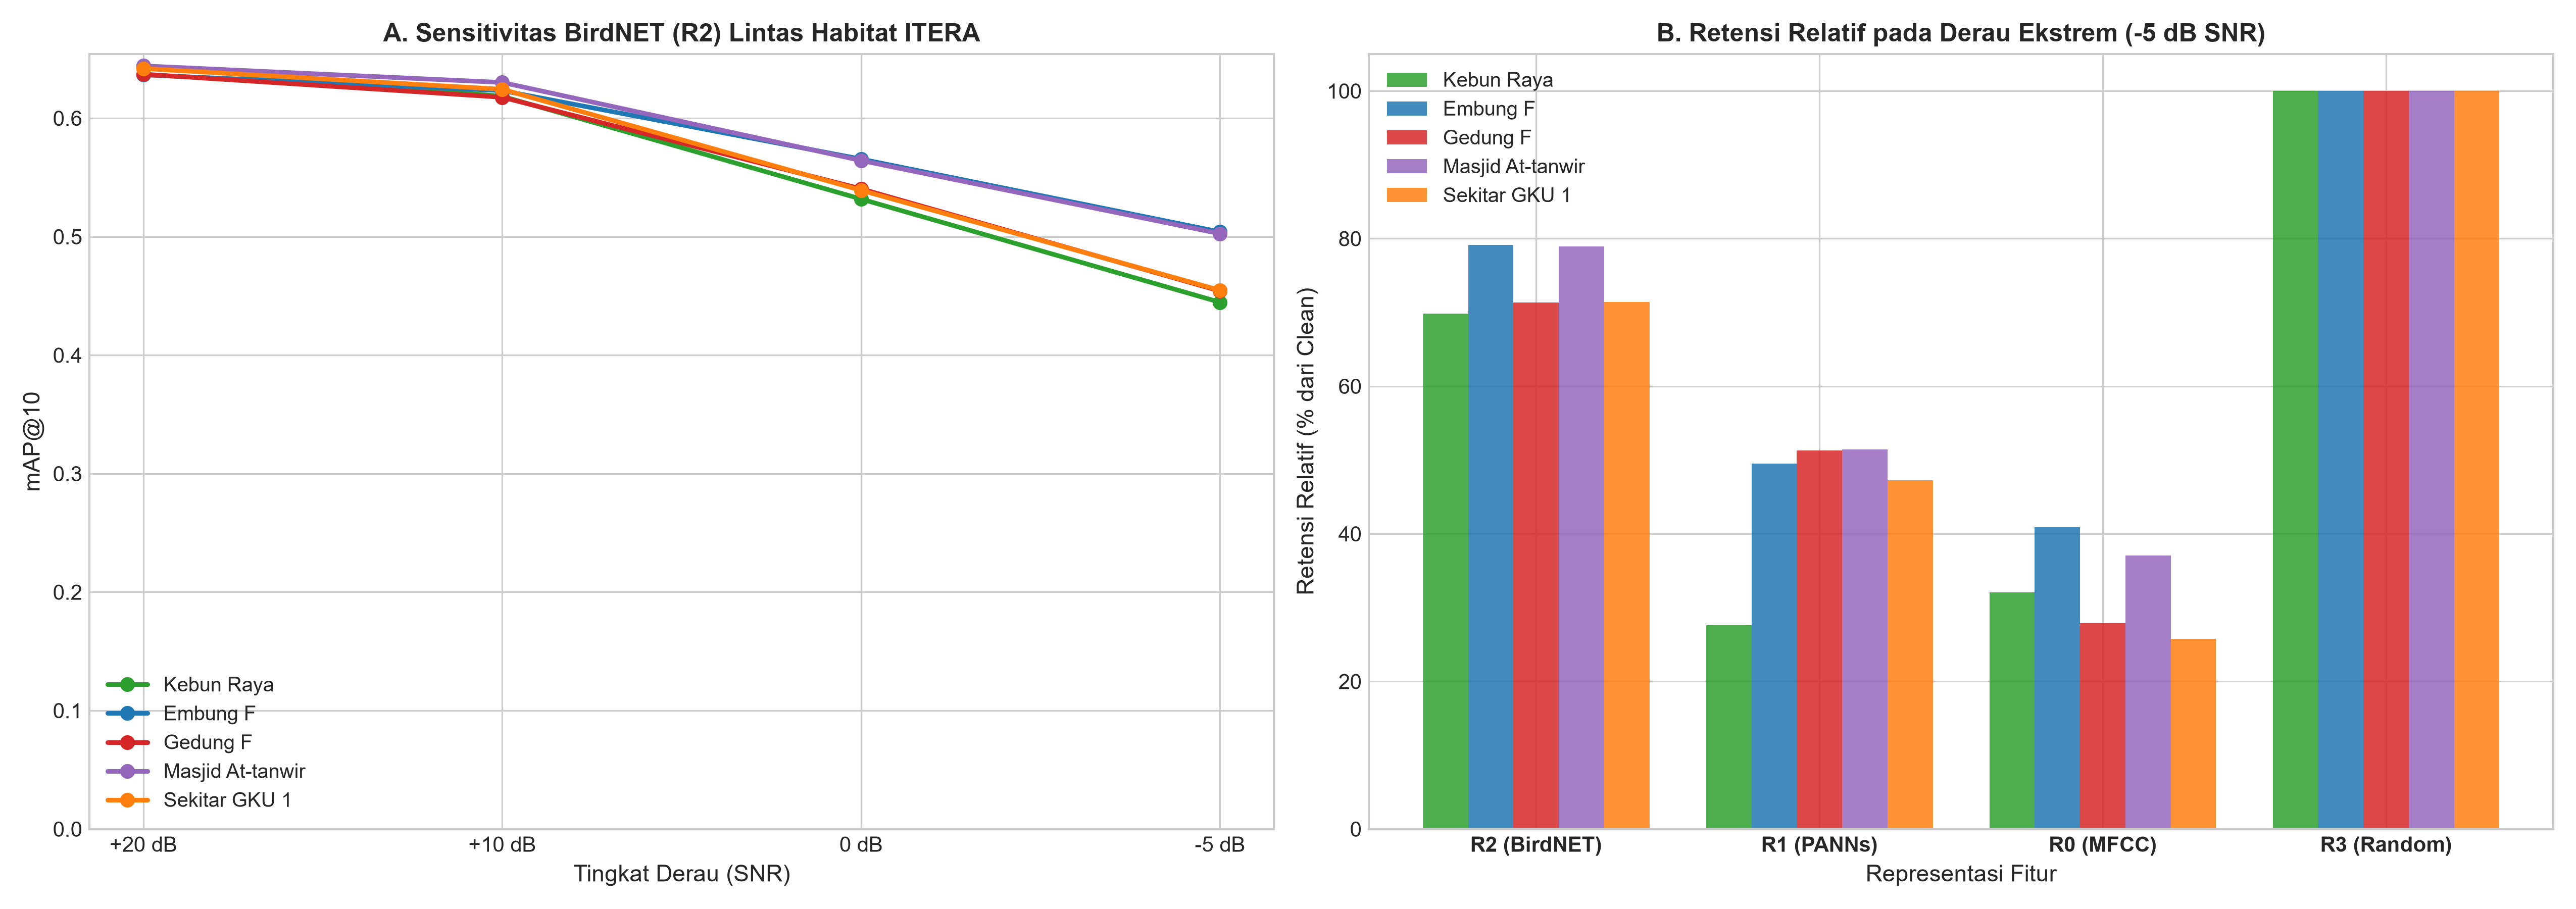

D:\FILE AND TASK\TA\results\reproductions\E4_5sites_20261011T213404_350219Z\raw\E4_R2_raw.csv | 25191 baris


,max_score,top1_match,RR,total_relevant_in_gallery,P@1,R@1,AP@1,P@5,R@5,AP@5,...,noise_attempt,noise_raw_rms,snr_db_target,snr_db_achieved,signal_power,noise_power_before_scaling,noise_gain,post_mix_gain,mix_skipped_silent_signal,noise_config
0,0.800407,1,1.000000,15,1.0,0.066667,1.0,1.0,0.333333,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.631527,1,1.000000,18,1.0,0.055556,1.0,0.8,0.222222,0.800000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.646827,1,1.000000,18,1.0,0.055556,1.0,0.4,0.111111,0.400000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.669163,1,1.000000,18,1.0,0.055556,1.0,0.8,0.222222,0.643333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.749145,0,0.500000,18,0.0,0.000000,0.0,0.8,0.222222,0.543333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.678046,1,1.000000,18,1.0,0.055556,1.0,0.8,0.222222,0.800000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25185,0.757342,1,1.000000,15,1.0,0.066667,1.0,1.0,0.333333,1.000000,...,1.0,0.045053,-5.0,-5.0,0.0025,0.002030,1.973529,1.0,False,Frequency-Low
25186,0.603117,1,1.000000,15,1.0,0.066667,1.0,0.6,0.200000,0.453333,...,1.0,0.028601,-5.0,-5.0,0.0025,0.000818,3.108759,1.0,False,Amplitudo-Low
25187,0.668094,0,0.025641,15,0.0,0.000000,0.0,0.0,0.000000,0.000000,...,1.0,0.046409,-5.0,-5.0,0.0025,0.002154,1.915880,1.0,False,Frequency-Medium
25188,0.668010,1,1.000000,15,1.0,0.066667,1.0,0.6,0.200000,0.483333,...,1.0,0.010809,-5.0,-5.0,0.0025,0.000117,8.225855,1.0,False,Amplitudo-Low


Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.
E4 raw menyediakan top1_match dan max_score, tetapi identitas Top-1, margin kelas, dan fitur noisy tidak tersedia.


In [3]:
run = ROOT / "results/reproductions/E4_5sites_20261011T213404_350219Z"
audit = ROOT / "results/reproductions/E4_audit_20261012T021801_989259Z"
show_json(run / "run_identity.json")
show_json(audit / "validation_report.json")
show_csv(run / "processed/e4_domain_shift_table.csv", rows=80)
for figure in sorted((run / "figures").glob("*.png")):
    print(figure.name)
    display(Image(filename=str(figure)))
show_csv(run / "raw/E4_R2_raw.csv", rows=12)
print("E4 raw menyediakan top1_match dan max_score, tetapi identitas Top-1, margin kelas, dan fitur noisy tidak tersedia.")


In [ ]:
# H3 memakai data mentah E4 yang sama; tidak ada audio yang dicampur ulang di sel ini.
h3_runs = sorted((ROOT / "results" / "reproductions").glob("H3_habitat_profile_stability_*"))
assert h3_runs, "Analisis H3 belum dibuat"
h3 = h3_runs[-1]
show_json(h3 / "metadata.json")
show_csv(h3 / "tables/h3_stability_summary.csv", rows=10)
show_csv(h3 / "tables/h3_retention_by_habitat_repeat.csv", rows=20)
print("Grafik H3:", h3 / "figures/h3_habitat_retention_stability.png")
display(Image(filename=str(h3 / "figures/h3_habitat_retention_stability.png")))
print("Interpretasi: ayunan = retensi lokasi tertinggi − terendah. H3 didukung bila CI selisih ayunan R1−R2 > 0.")
